# Final Project - TP4620 Vasileios Troupis

### Import Libraries

In [1]:
# pandas
import pandas as pd

#matplotlib
import matplotlib.pyplot as plt

# sklearn
from sklearn import preprocessing
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import MultinomialNB

# numpy
import numpy as np

# yellowbrick
from yellowbrick.cluster import KElbowVisualizer , SilhouetteVisualizer

# scipy
from scipy.cluster.hierarchy import ward, dendrogram,linkage

import warnings
warnings.filterwarnings('ignore')

# STEP 1 – Data Selection

--------------------------------------------------------------------------------------------------------------------------------------------------------------

Import the breast-cancer-wisconsin.data

--------------------------------------------------------------------------------------------------------------------------------------------------------------

In [2]:
data_set = pd.read_csv("breast-cancer-wisconsin.data")

data_set

,1000025,5,1,1.1,1.2,2,1.3,3,1.4,1.5,2.1
0,1002945,5,4,4,5,7,10,3,2,1,2
1,1015425,3,1,1,1,2,2,3,1,1,2
2,1016277,6,8,8,1,3,4,3,7,1,2
3,1017023,4,1,1,3,2,1,3,1,1,2
4,1017122,8,10,10,8,7,10,9,7,1,4
...,...,...,...,...,...,...,...,...,...,...,...
693,776715,3,1,1,1,3,2,1,1,1,2
694,841769,2,1,1,1,2,1,1,1,1,2
695,888820,5,10,10,3,7,3,8,10,2,4
696,897471,4,8,6,4,3,4,10,6,1,4


In [3]:
#name the columns on dataset
column_names = ['Sample code number' ,'Clump Thickness', 'Uniformity of Cell Size' ,'Uniformity of Cell Shape', 'Marginal Adhesion', 'Single Epithelial Cell Size', 'Bare Nuclei', 'Bland Chromatin','Normal Nucleoli','Mitoses','Class']
data_set.columns = column_names


# Remove ID, Sample code number Column  
data_set = data_set.drop('Sample code number', 1)


data_set

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,4,4,5,7,10,3,2,1,2
1,3,1,1,1,2,2,3,1,1,2
2,6,8,8,1,3,4,3,7,1,2
3,4,1,1,3,2,1,3,1,1,2
4,8,10,10,8,7,10,9,7,1,4
...,...,...,...,...,...,...,...,...,...,...
693,3,1,1,1,3,2,1,1,1,2
694,2,1,1,1,2,1,1,1,1,2
695,5,10,10,3,7,3,8,10,2,4
696,4,8,6,4,3,4,10,6,1,4


# Step 2 – Data inspection

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

 As i saw in the documantation of the data set, it has 16 missing values so i will drop them because they will not affect the results.
 
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 

In [4]:
drop_list = data_set[data_set.values == '?'].index.tolist()
data_set.drop(drop_list, inplace = True)
data_set.round(2)

,Clump Thickness,Uniformity of Cell Size,Uniformity of Cell Shape,Marginal Adhesion,Single Epithelial Cell Size,Bare Nuclei,Bland Chromatin,Normal Nucleoli,Mitoses,Class
0,5,4,4,5,7,10,3,2,1,2
1,3,1,1,1,2,2,3,1,1,2
2,6,8,8,1,3,4,3,7,1,2
3,4,1,1,3,2,1,3,1,1,2
4,8,10,10,8,7,10,9,7,1,4
...,...,...,...,...,...,...,...,...,...,...
693,3,1,1,1,3,2,1,1,1,2
694,2,1,1,1,2,1,1,1,1,2
695,5,10,10,3,7,3,8,10,2,4
696,4,8,6,4,3,4,10,6,1,4


--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Im using the decribe method to see the details of each column.

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [5]:
for j in data_set.columns:
    print(data_set[j].describe())

count    682.000000
mean       4.441349
std        2.822751
min        1.000000
25%        2.000000
50%        4.000000
75%        6.000000
max       10.000000
Name: Clump Thickness, dtype: float64
count    682.000000
mean       3.153959
std        3.066285
min        1.000000
25%        1.000000
50%        1.000000
75%        5.000000
max       10.000000
Name: Uniformity of Cell Size, dtype: float64
count    682.000000
mean       3.218475
std        2.989568
min        1.000000
25%        1.000000
50%        1.000000
75%        5.000000
max       10.000000
Name: Uniformity of Cell Shape, dtype: float64
count    682.000000
mean       2.832845
std        2.865805
min        1.000000
25%        1.000000
50%        1.000000
75%        4.000000
max       10.000000
Name: Marginal Adhesion, dtype: float64
count    682.000000
mean       3.236070
std        2.224214
min        1.000000
25%        2.000000
50%        2.000000
75%        4.000000
max       10.000000
Name: Single Epithelial Cell 

# STEP 3 – Data Prepossessing

In [6]:
# Set the features and the target

data_features = ['Clump Thickness', 'Uniformity of Cell Size' ,'Uniformity of Cell Shape', 'Marginal Adhesion', 'Single Epithelial Cell Size', 'Bare Nuclei', 'Bland Chromatin','Normal Nucleoli','Mitoses']
data_target = ['Class']

X = np.array(data_set[data_features])
y = np.array(data_set[data_target])

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Plot the dataframe with boxplot to chech if i have outliers

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [7]:
min_max_scaler = preprocessing.MinMaxScaler()
X = min_max_scaler.fit_transform(X)
y = min_max_scaler.fit_transform(y)

data_frame = pd.DataFrame(X)

# data_frame

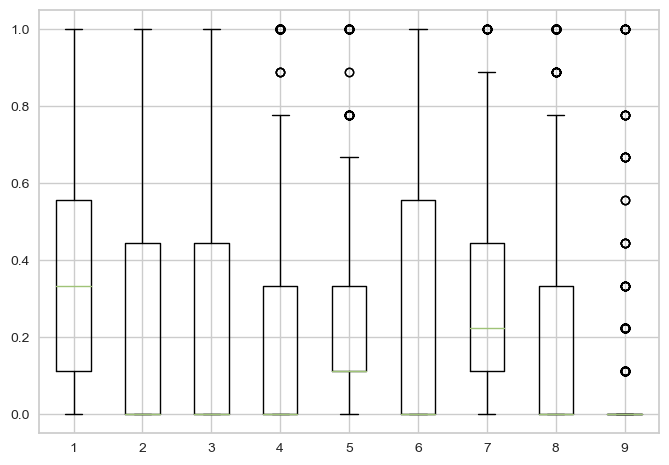

In [8]:
plt.boxplot(data_frame)
plt.show()

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

As i see i have so i have to remove them. The Mitoses Colunm is 0 so with the IQR calculation will be still 0 and it will be removes if i will not make it 1. 

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [9]:
# calculate the IQR

for j in data_frame.columns:
    Q1 = data_frame[j].quantile(0.25)
    Q3 = data_frame[j].quantile(0.75)
    IQR = Q3 - Q1
    if IQR == 0:
        IQR = 1
        
    # remove outlier based on the IQR        
    data_frame = data_frame[(data_frame[j] < (Q1 - 1.5 * IQR)) | (data_frame[j] > (Q3 + 1.5 * IQR))]

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

I removed the ouliers, so i will min maxscale the data

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [10]:
# Set the features and the target

data_features = ['Clump Thickness', 'Uniformity of Cell Size' ,'Uniformity of Cell Shape', 'Marginal Adhesion', 'Single Epithelial Cell Size', 'Bare Nuclei', 'Bland Chromatin','Normal Nucleoli','Mitoses']
data_target = ['Class']

X = np.array(data_set[data_features])
y = np.array(data_set[data_target])

In [11]:
min_max_scaler = preprocessing.MinMaxScaler()
X = min_max_scaler.fit_transform(X)
y = min_max_scaler.fit_transform(y)

data_frame = pd.DataFrame(X)
data_frame

,0,1,2,3,4,5,6,7,8
0,0.444444,0.333333,0.333333,0.444444,0.666667,1.000000,0.222222,0.111111,0.000000
1,0.222222,0.000000,0.000000,0.000000,0.111111,0.111111,0.222222,0.000000,0.000000
2,0.555556,0.777778,0.777778,0.000000,0.222222,0.333333,0.222222,0.666667,0.000000
3,0.333333,0.000000,0.000000,0.222222,0.111111,0.000000,0.222222,0.000000,0.000000
4,0.777778,1.000000,1.000000,0.777778,0.666667,1.000000,0.888889,0.666667,0.000000
...,...,...,...,...,...,...,...,...,...
677,0.222222,0.000000,0.000000,0.000000,0.222222,0.111111,0.000000,0.000000,0.000000
678,0.111111,0.000000,0.000000,0.000000,0.111111,0.000000,0.000000,0.000000,0.000000
679,0.444444,1.000000,1.000000,0.222222,0.666667,0.222222,0.777778,1.000000,0.111111
680,0.333333,0.777778,0.555556,0.333333,0.222222,0.333333,1.000000,0.555556,0.000000


# Step 4 – Supervised learning (Classification)

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Split the data set to 70% - 30% 

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Linear Discriminant Analysis

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [13]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)
l_y_pred=lda.predict(X_test)

In [14]:
results = classification_report(y_test, l_y_pred)
print('Linear Discriminant Analysis')
print('70% - 30%:', results, sep='\n')

Linear Discriminant Analysis
70% - 30%:
              precision    recall  f1-score   support

         0.0       0.96      1.00      0.98       132
         1.0       1.00      0.92      0.96        73

    accuracy                           0.97       205
   macro avg       0.98      0.96      0.97       205
weighted avg       0.97      0.97      0.97       205



Quadratic Discriminant Analysis

In [15]:
qda = QuadraticDiscriminantAnalysis(reg_param=np.finfo(float).eps)
qda.fit(X_train,y_train)
yq_pred=qda.predict(X_test)

In [16]:
results = classification_report(y_test, yq_pred)
print('Quadratic Discriminant Analysis')
print('70% - 30%:', results, sep='\n')

Quadratic Discriminant Analysis
70% - 30%:
              precision    recall  f1-score   support

         0.0       0.97      0.97      0.97       132
         1.0       0.95      0.95      0.95        73

    accuracy                           0.96       205
   macro avg       0.96      0.96      0.96       205
weighted avg       0.96      0.96      0.96       205



--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Split the data set to 80% - 20% 

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2)

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Linear Discriminant Analysis

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [18]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)
l_y_pred=lda.predict(X_test)

In [19]:
results = classification_report(y_test, l_y_pred)
print('Linear Discriminant Analysis')
print('80% - 20%:', results, sep='\n')

Linear Discriminant Analysis
80% - 20%:
              precision    recall  f1-score   support

         0.0       0.96      0.99      0.97        95
         1.0       0.97      0.90      0.94        42

    accuracy                           0.96       137
   macro avg       0.97      0.95      0.96       137
weighted avg       0.96      0.96      0.96       137



--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Quadratic Discriminant Analysis

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [20]:
qda = QuadraticDiscriminantAnalysis(reg_param=np.finfo(float).eps)
qda.fit(X_train,y_train)
yq_pred=qda.predict(X_test)

In [21]:
results = classification_report(y_test, yq_pred)
print('Quadratic Discriminant Analysis')
print('80% - 20%:', results, sep='\n')

Quadratic Discriminant Analysis
80% - 20%:
              precision    recall  f1-score   support

         0.0       0.99      0.95      0.97        95
         1.0       0.89      0.98      0.93        42

    accuracy                           0.96       137
   macro avg       0.94      0.96      0.95       137
weighted avg       0.96      0.96      0.96       137



--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Split the data set to 90% - 10% 

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.1)

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Linear Discriminant Analysis

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [23]:
lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)
l_y_pred=lda.predict(X_test)

In [24]:
results = classification_report(y_test, l_y_pred)
print('Linear Discriminant Analysis')
print('90% - 10%:', results, sep='\n')

Linear Discriminant Analysis
90% - 10%:
              precision    recall  f1-score   support

         0.0       0.98      1.00      0.99        47
         1.0       1.00      0.95      0.98        22

    accuracy                           0.99        69
   macro avg       0.99      0.98      0.98        69
weighted avg       0.99      0.99      0.99        69



--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Quadratic Discriminant Analysis

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [25]:
qda = QuadraticDiscriminantAnalysis(reg_param=np.finfo(float).eps)
qda.fit(X_train,y_train)
yq_pred=qda.predict(X_test)

In [26]:
results = classification_report(y_test, yq_pred)
print('Quadratic Discriminant Analysis')
print('90% - 10%:', results, sep='\n')

Quadratic Discriminant Analysis
90% - 10%:
              precision    recall  f1-score   support

         0.0       0.98      0.98      0.98        47
         1.0       0.95      0.95      0.95        22

    accuracy                           0.97        69
   macro avg       0.97      0.97      0.97        69
weighted avg       0.97      0.97      0.97        69



--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Both classifiers has good result. The Linear is a little bit better. Both classifiers have better score for the category A, maybe because we have more data on this category than the B.

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

# Step 5 – Unsupervised learning (k-means)


In [27]:
model = KMeans()
visualizer = KElbowVisualizer(model, k=(1,11), timings=False ,locate_elbow=False)

KElbowVisualizer(ax=<AxesSubplot: >, estimator=KMeans(n_clusters=10), k=(1, 11),
                 locate_elbow=False, timings=False)

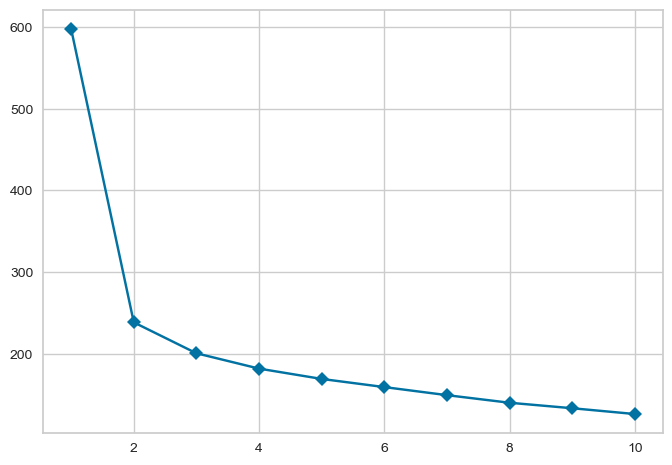

In [28]:
visualizer.fit(data_frame)

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 
 As i see after 2 clusters the results is almost the same so i will pick 2 clusters for the k-means. 
 
--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

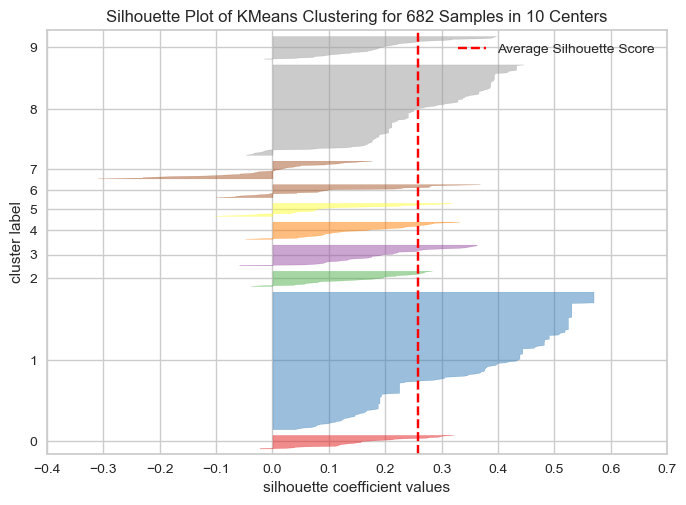

In [29]:
visualizer1 = SilhouetteVisualizer(model)
visualizer1.fit(data_frame) # Fit the data to the visualizer
visualizer1.show();

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

With the SilhouetteVisualizer i see the average score is something between 2 and 3. So i will pick 2 clusters.

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3) 
kmeans = KMeans(n_clusters = 2).fit(X_train)
k_pred = kmeans.predict(X_test)

In [31]:
results = classification_report(y_test,k_pred)
print('K-Means')
print('70% - 30%:', results, sep='\n')

K-Means
70% - 30%:
              precision    recall  f1-score   support

         0.0       0.97      0.98      0.97       135
         1.0       0.96      0.94      0.95        70

    accuracy                           0.97       205
   macro avg       0.96      0.96      0.96       205
weighted avg       0.97      0.97      0.97       205



--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
 
The results are good.

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


# Step 6 – Unsupervised learning (Hierarchal Clustering)


In [32]:
np.set_printoptions(precision = 4, suppress=True)
distance = linkage(data_frame, 'ward')

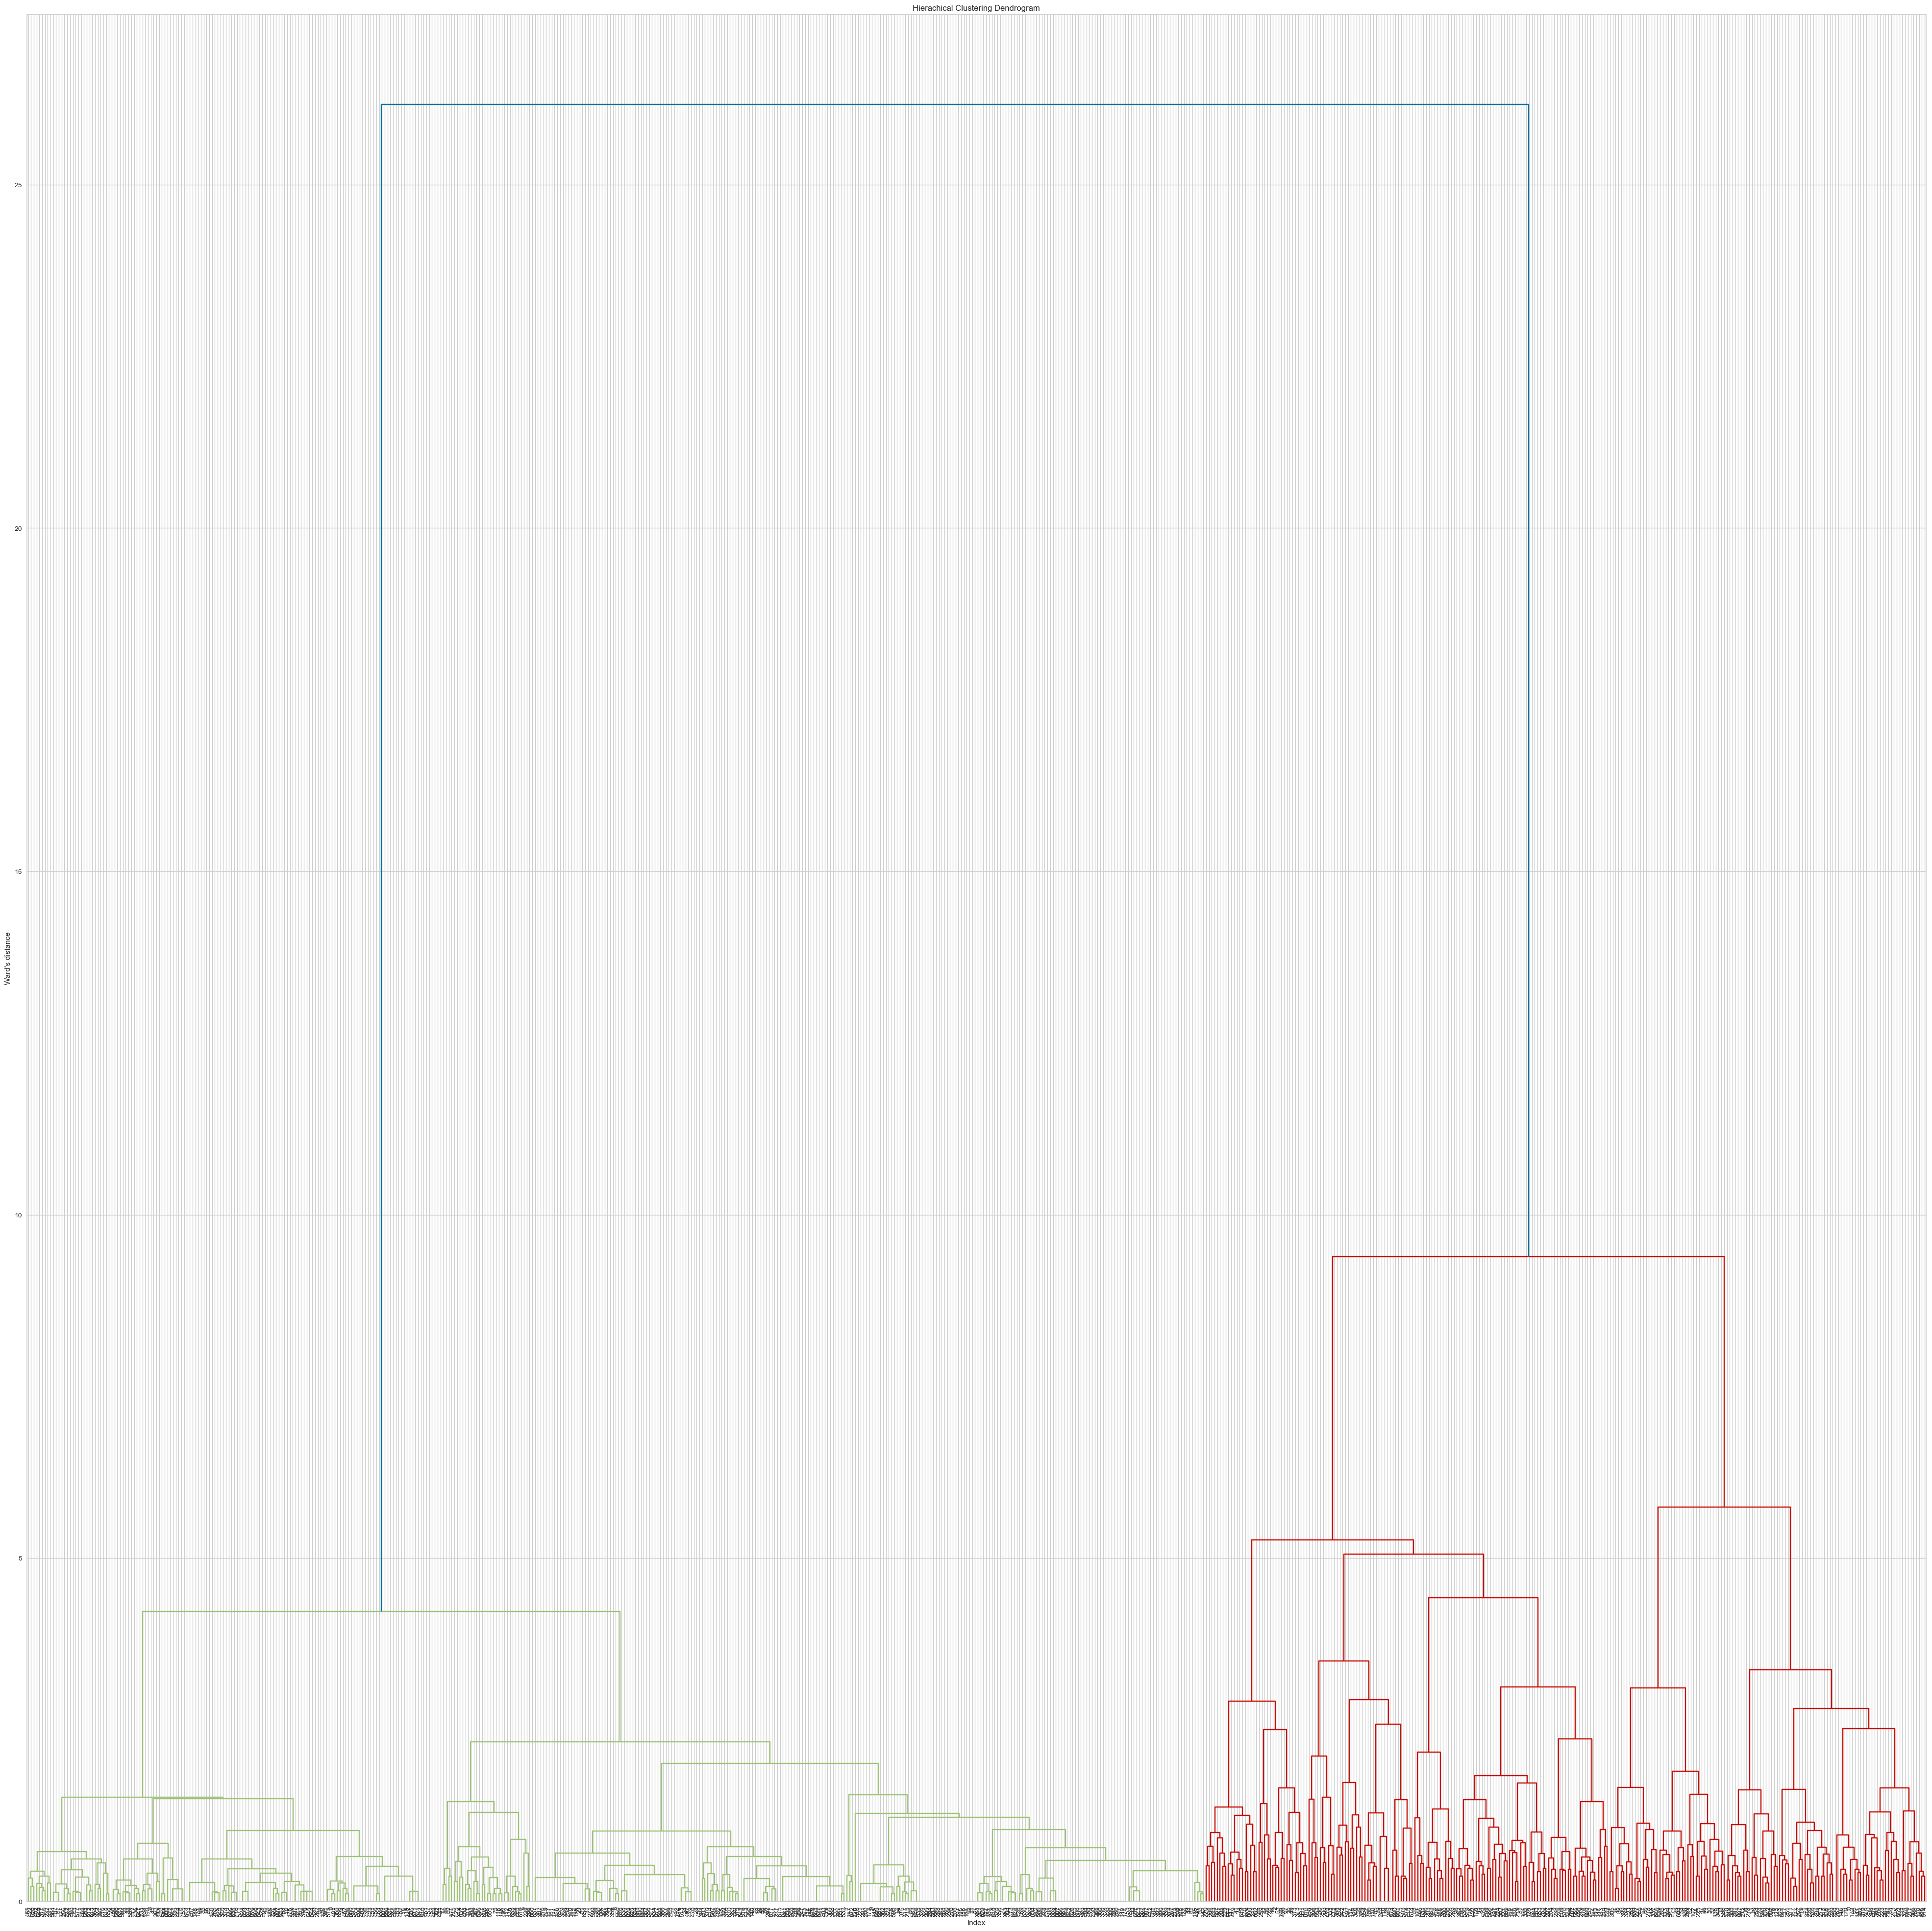

In [33]:
plt.figure(figsize = (50,50))
plt.title("Hierachical Clustering Dendrogram")
plt.xlabel("Index")
plt.ylabel("Ward's distance")
dendrogram(distance,
 leaf_rotation = 90.,
 leaf_font_size = 9.,);

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

As i see the dendrogram, i have alot of data looking the same so maybe some of the benign cancer are looking like malignant cancer and the opposite.

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


# Step 7 – Naïve Bayes


In [34]:
nbm = MultinomialNB()
nbm.fit(X_train, y_train)
NAIVE = nbm.predict(X_test)

In [35]:
results = classification_report(y_test,NAIVE)
print('Naïve Bayes')
print('results:', results, sep='\n')

Naïve Bayes
results:
              precision    recall  f1-score   support

         0.0       0.90      0.98      0.94       135
         1.0       0.95      0.79      0.86        70

    accuracy                           0.91       205
   macro avg       0.92      0.88      0.90       205
weighted avg       0.92      0.91      0.91       205



--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Naïve Bayes as i see doesnt have good enough results than the supervised learning.

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------


# Step 8 – Conclusion 


--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

As i see the results of the Supervised learning i understand that this method has better results for this problem.
Also for the Supervised learning as smaller is the test set, the better the score.

--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
